# 01: Data Loading and Diagnosis

This notebook covers the initial data loading, construction of the master dataframe, and the data diagnosis phase. Its output is `checkpoint_end_Data_Diagnosis.pkl`, which is the input for `02_feature_selection.ipynb`.

**Input:** `target.csv`, `X.csv`  
**Output:** `data/processed/checkpoint_end_Data_Diagnosis.pkl`

---

## Project Overview

This project focuses on the development of a complete Credit Risk Modeling framework using consumer loan data originated by Lending Club. The main objective is to estimate the total expected economic loss associated with a loan portfolio acquisition under the Basel II/III framework:

$$
\text{Expected Loss (EL)} = PD \times LGD \times EAD
$$

Where:
- **PD (Probability of Default):** likelihood that a borrower will default.
- **LGD (Loss Given Default):** percentage of exposure lost in the event of default.
- **EAD (Exposure at Default):** total exposure at the time of default (`funded_amnt`).

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

from feature_selection import diagnose_features
from feature_plot import (
    analyze_zero_variance_feature,
    analyze_categorical_feature,
    plot_continuous_variable_categoric_feature,
    plot_boxplots_list,
    plot_scatter_list
)
from feature_statistics import compare_distributions
from feature_engineering import group_emp_title, clean_emp_length

## 1. Data Load

In [3]:
# Load target and feature CSVs and merge into a single dataframe
target_df = pd.read_csv(r"data/raw/target.csv")
X_df      = pd.read_csv(r"data/raw/X.csv")

df = pd.concat([target_df, X_df], axis=1)
df.head()

,y,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,...,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year
0,0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,...,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001
1,0,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,...,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987
2,0,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,...,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011
3,0,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,...,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006
4,0,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,...,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000


In [4]:
# Dataset spans loans originated between 2007 and 2018
df["issue_date_year"].describe()

count    2.139643e+06
mean     2.015766e+03
std      1.791998e+00
min      2.007000e+03
25%      2.015000e+03
50%      2.016000e+03
75%      2.017000e+03
max      2.018000e+03
Name: issue_date_year, dtype: float64

In [5]:
# Default rate: approximately 13%, stratified target
print(f"Default rate: {df['y'].mean():.4f}")
print(f"Dataset shape: {df.shape}")

Default rate: 0.1307
Dataset shape: (2139643, 46)


## 2. Master Dataframe Construction

Two independent models will be trained, a classification model for PD and a regression model for LGD. Each model operates on a different population and requires a different target variable:

- **PD target:** binary variable `Target_Variable_Default` (0/1)
- **EAD:** `funded_amnt` (original loan amount at origination)
- **LGD target:** `Target_Variable_Loss`, the net loss on a defaulted loan as a percentage of EAD

The LGD target is built from what the lender actually got back. Total payments received (`paym_rec_for_tot_amnt_fund`) are the sum of principal, interest, late fees and post-default recoveries, so the recoveries are what remains after the three scheduled components:

```
recoveries = paym_rec_for_tot_amnt_fund - princ_rec - interest_rec - late_fees_rec
net_loss   = EAD - princ_rec - recoveries        (clipped to [0, EAD])
LGD (%)    = 100 * net_loss / EAD
```

Interest received is not netted against the loss: LGD measures the share of the exposure that is not recovered, not the profitability of the loan. Collection fees are not in the dataset, so recoveries are gross and the LGD is slightly understated.

LGD is expressed relative to EAD at origination (not to the outstanding balance at the moment of default), so that `EL = PD x LGD x EAD` uses one consistent exposure.

The payment variables used here are observed after origination. They define the target but must never be used as model features (see the leakage lists in `02_feature_selection`).

In [6]:
# Build master dataframe with both target variables
df_master = df.copy()
df_master = df_master.rename(columns={"y": "Target_Variable_Default", "funded_amnt": "EAD"})

# LGD target: net loss as a percentage of EAD (see the markdown above)
recoveries = (
    df_master["paym_rec_for_tot_amnt_fund"]
    - df_master["princ_rec"]
    - df_master["interest_rec"]
    - df_master["late_fees_rec"]
).clip(lower=0)
net_loss = (df_master["EAD"] - df_master["princ_rec"] - recoveries).clip(lower=0)
net_loss = net_loss.where(net_loss <= df_master["EAD"], df_master["EAD"])
df_master.insert(1, "Target_Variable_Loss", 100 * net_loss / df_master["EAD"])

df_master.head()

,Target_Variable_Default,Target_Variable_Loss,EAD,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,...,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year
0,0,95.440800,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,...,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001
1,0,97.959167,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,...,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987
2,0,95.744200,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,...,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011
3,0,95.798250,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,...,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006
4,0,97.796733,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,...,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000


In [7]:
# Sanity checks on the LGD target (fail loud if the payment identity does not hold)
defaulted = df_master["Target_Variable_Default"] == 1
lgd_default = df_master.loc[defaulted, "Target_Variable_Loss"]

assert lgd_default.between(0, 100).all(), "LGD outside [0, 100]"

# For loans that did not default, implied recoveries should be essentially zero.
implied_recoveries = (
    df_master["paym_rec_for_tot_amnt_fund"]
    - df_master["princ_rec"]
    - df_master["interest_rec"]
    - df_master["late_fees_rec"]
)
print("Implied recoveries, non-defaulted loans (should be ~0):")
print(implied_recoveries[~defaulted].describe().round(2))

print("\nLGD on defaulted loans (%):")
print(lgd_default.describe().round(2))
print(f"Share at 0%: {(lgd_default == 0).mean():.3f} | share at 100%: {(lgd_default == 100).mean():.3f}")

Implied recoveries, non-defaulted loans (should be ~0):
count    1859927.00
mean          -0.00
std            0.00
min           -0.01
25%           -0.00
50%            0.00
75%            0.00
max            0.01
dtype: float64

LGD on defaulted loans (%):
count    279716.00
mean         62.20
std          22.00
min           0.00
25%          47.97
50%          66.28
75%          79.05
max         100.00
Name: Target_Variable_Loss, dtype: float64
Share at 0%: 0.004 | share at 100%: 0.003


### 2.1 Development sample: matured loans

Both targets are only fully observed once a loan has reached the end of its term. The dataset is a snapshot taken after the last issue month (December 2018), so recent vintages are truncated: a 2018 loan that is already in default must have failed very early, having repaid almost no principal, while the 2018 loans that will default later still appear as performing. The effect is visible in the data:

- the observed default rate falls from 17-18% for 2014-2015 issues to 2.9% for 2018 issues, which understates PD on recent vintages;
- the net-loss LGD of defaulted loans is stable at 54-59% for 2007-2015 issues and then rises to 62%, 74% and 89% for 2016, 2017 and 2018. Restricting to defaults with no principal outstanding does not remove the drift, so it comes from early defaults dominating young vintages, not from open recoveries.

Models are therefore **developed on matured loans only**: loans whose full term has elapsed by the snapshot (36-month loans issued up to December 2015, 60-month loans issued up to December 2013). Every loan in the portfolio is still **scored** for the Expected Loss, matured or not. This is the usual practice for lifetime PD and LGD: estimate on cohorts with complete outcomes, apply to the whole book.

In [8]:
# Snapshot = last issue month in the data. A loan is matured when issue date + term <= snapshot.
month = df_master["issue_date_month"]
if not pd.api.types.is_numeric_dtype(month):
    month = pd.to_datetime(month.astype(str).str[:3], format="%b").dt.month
issue_index = df_master["issue_date_year"] * 12 + month - 1          # months since year 0
snapshot_index = issue_index.max()
df_master["is_matured"] = (issue_index + df_master["loan_term_months"] <= snapshot_index).astype(int)

snapshot = f"{snapshot_index // 12}-{snapshot_index % 12 + 1:02d}"
print(f"Snapshot (last issue month): {snapshot}")
print(f"Matured loans: {df_master['is_matured'].sum():,} of {len(df_master):,} "
      f"({df_master['is_matured'].mean():.1%})")

# Evidence for the restriction: default rate and LGD by issue year
by_year = df_master.groupby("issue_date_year").agg(
    loans=("Target_Variable_Default", "size"),
    matured_share=("is_matured", "mean"),
    default_rate=("Target_Variable_Default", "mean"),
)
by_year["lgd_mean_defaulted"] = (
    df_master[df_master["Target_Variable_Default"] == 1]
    .groupby("issue_date_year")["Target_Variable_Loss"].mean()
)
print(by_year.round(3).to_string())

dev = df_master[df_master["is_matured"] == 1]
print(f"\nDevelopment sample: {len(dev):,} loans | default rate {dev['Target_Variable_Default'].mean():.4f} | "
      f"defaults {int(dev['Target_Variable_Default'].sum()):,} | "
      f"mean LGD on defaults {dev.loc[dev['Target_Variable_Default'] == 1, 'Target_Variable_Loss'].mean():.2f}")

Snapshot (last issue month): 2018-12
Matured loans: 676,113 of 2,139,643 (31.6%)
                  loans  matured_share  default_rate  lgd_mean_defaulted
issue_date_year                                                         
2007                574          1.000         0.270              56.624
2008               2393          1.000         0.207              58.371
2009               5279          1.000         0.137              58.601
2010              12537          1.000         0.140              58.060
2011              21721          1.000         0.152              59.486
2012              53361          1.000         0.162              56.176
2013             134797          1.000         0.156              54.475
2014             235588          0.690         0.176              54.992
2015             420551          0.673         0.183              58.220
2016             425567          0.000         0.167              62.217
2017             401094          0.000     


Development sample: 676,113 loans | default rate 0.1488 | defaults 100,589 | mean LGD on defaults 52.24


In [9]:
# Initialize working dataframe: df_master is kept as the unmodified control
df_master_features = df_master.copy()

# Feature lists will be populated as predictive features are identified
features_predictive_power_PD  = []
features_predictive_power_LGD = []

## 3. Data Diagnosis

Before performing deep EDA, features are screened for three conditions that may bias or artificially inflate predictive performance:

1. **High NaN percentage** (>5%): substantial information loss
2. **High cardinality with low-frequency categories**: statistical noise
3. **Low variance**: single category representing >90% of observations

Features flagged here are reviewed individually and treated via feature engineering rather than discarded automatically.

In [10]:
# Run automated diagnosis
diagnosis = diagnose_features(df_master_features)
diagnosis

⚠ Features flagged for manual review: 20
  · Zero_Variance   : 2  → safe to discard directly
  · High_Cardinality: 5  → requires encoding decision
  · NaNs_Number     : 14  → requires imputation strategy


,feature,dtype,pct_NaNs,n_categories,min_category_freq_pct,top_value_freq_pct,reason
0,late_fees_rec,numeric,0.00,NaN,NaN,96.24,Zero_Variance
1,disbursement_method,categorical,0.00,2.0,3.4180,96.58,Zero_Variance
2,emp_title,categorical,6.94,496831.0,0.0000,1.75,"High_Cardinality, NaNs_Number"
3,grade,categorical,0.00,35.0,0.0689,6.45,High_Cardinality
4,home_ownership_status,categorical,0.00,4.0,0.0572,48.20,High_Cardinality
5,loan_purpose,categorical,0.00,14.0,0.0198,56.38,High_Cardinality
6,addr_state,categorical,0.00,51.0,0.0007,14.05,High_Cardinality
7,mths_since_recent_bankcard_delinq,numeric,76.81,NaN,NaN,1.55,NaNs_Number
8,mths_since_recent_revol_delinq,numeric,67.02,NaN,NaN,1.81,NaNs_Number
9,mths_since_last_delinq,numeric,50.99,NaN,NaN,1.90,NaNs_Number


## 4. Zero Variance Features

### 4.1 `late_fees_rec`

Represents late fees received to date. 96.24% of observations are 0, but the defaulted population may behave differently.

In [11]:
df_master_features["late_fees_rec"].value_counts()

late_fees_rec
0.000000      2059269
15.000000       16967
30.000000        3435
45.000000        1148
60.000000         469
               ...   
227.150000          1
101.840000          1
96.660000           1
86.640000           1
88.440001           1
Name: count, Length: 17601, dtype: int64

── Frequency table (% within each group) ──────────────────
                   Target_Variable_Default = 0  Target_Variable_Default = 1  pct_rows
has_value                                                                            
late_fees_rec = 0                        88.32                        11.68     96.24
late_fees_rec > 0                        51.19                        48.81      3.76

Base rates  →  Target_Variable_Default=0: 86.93%  |  Target_Variable_Default=1: 13.07%


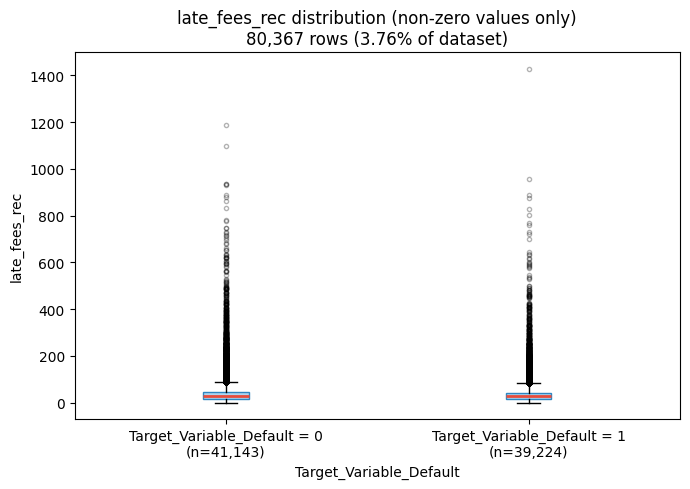

In [12]:
# Frequency table and distribution analysis vs PD target
analyze_zero_variance_feature(df_master_features, feature="late_fees_rec", target="Target_Variable_Default")

In [13]:
# Statistical significance: p-value and Cohen's d
# Having late fees (binary) is highly predictive; fee amount is not
compare_distributions(df_master_features, feature="Target_Variable_Default", target="late_fees_rec", alpha=0.05)

Compared groups: 0 vs 1
Means:            0.88 vs 5.29
Medians:          0.00 vs 0.00
Mann-Whitney U:    229409596393
p-value:           0.0000 → significative difference
Cohen's d:         0.279 → small effect


In [14]:
# PD: encode as binary flag: having late fees vs not
df_master_features["has_late_fees_PD"] = (df_master_features["late_fees_rec"] > 0).astype(int)
features_predictive_power_PD.append("has_late_fees_PD")

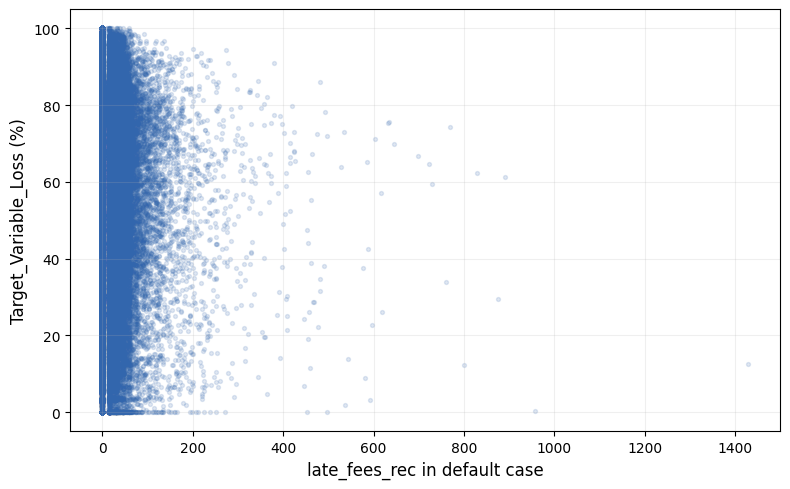

In [15]:
# LGD: analyze predictive power over Target_Variable_Loss on defaulted population
df_master_features_default = df_master_features[df_master_features["Target_Variable_Default"] == 1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    df_master_features_default['late_fees_rec'],
    df_master_features_default['Target_Variable_Loss'],
    alpha=0.15, s=8, color='#3266ad'
)
ax.set_xlabel('late_fees_rec in default case', fontsize=12)
ax.set_ylabel('Target_Variable_Loss (%)', fontsize=12)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [16]:
# LGD: clip at 99.9th percentile to handle long upper tail
quantile_999 = df_master_features_default['late_fees_rec'].quantile(0.999)
df_master_features["late_fees_rec_LGD"] = df_master_features["late_fees_rec"].clip(upper=quantile_999)
features_predictive_power_LGD.append("late_fees_rec_LGD")

# Drop original feature
df_master_features = df_master_features.drop(columns="late_fees_rec")

### 4.2 `disbursement_method`

Method by which the borrower receives the loan (Cash vs DirectPay). DirectPay borrowers show substantially lower default rates.

In [17]:
analyze_categorical_feature(df_master_features, feature="disbursement_method", target="Target_Variable_Default")

── Frequency table (% within each category) ───────────────
                     Target_Variable_Default = 0  Target_Variable_Default = 1  pct_rows
disbursement_method                                                                    
Cash                                       86.55                        13.45     96.58
DirectPay                                  97.62                         2.38      3.42

Base rates  →  Target_Variable_Default=0: 86.93%  |  Target_Variable_Default=1: 13.07%


In [18]:
# PD: encode as binary flag: DirectPay vs Cash
df_master_features["is_directpay_PD"] = (df_master_features["disbursement_method"] == "DirectPay").astype(int)
features_predictive_power_PD.append("is_directpay_PD")

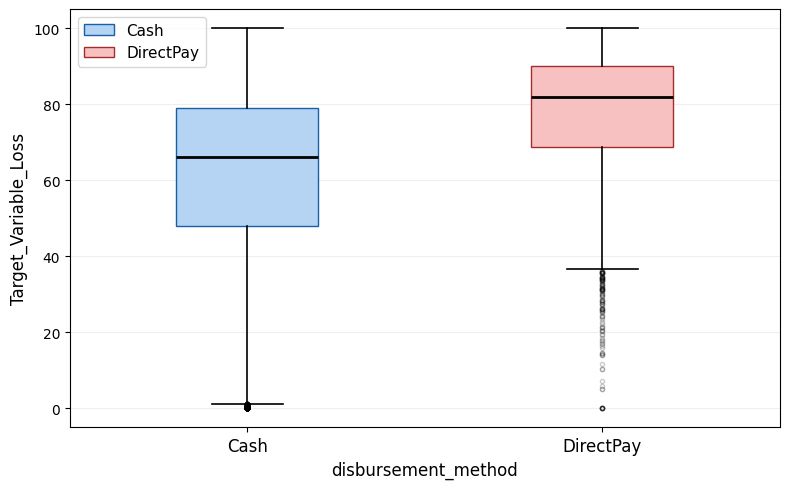

Compared groups: Cash vs DirectPay
Means:            62.12 vs 76.18
Medians:          66.17 vs 81.99
Mann-Whitney U:    141833782
p-value:           0.0000 → significative difference
Cohen's d:         0.676 → moderate effect


In [19]:
# LGD: small effect size (Cohen's d = 0.235), no practical predictive power over loss severity
plot_continuous_variable_categoric_feature(df=df_master_features_default, feature="disbursement_method", target="Target_Variable_Loss")
compare_distributions(df=df_master_features_default, feature='disbursement_method', target='Target_Variable_Loss')

In [20]:
# LGD: keep with renamed column for completeness: will be filtered in feature selection
df_master_features["disbursement_method_LGD"] = df_master_features["disbursement_method"]
df_master_features = df_master_features.drop(columns="disbursement_method")

## 5. High NaN Features

### 5.1 `mths_since_*` variables

NaNs in these variables are MNAR (Missing Not At Random): they represent borrowers who have never had the corresponding delinquency event. NaNs are imputed with sentinel value 999 (meaning the event happened a long time ago or never occurred).

In [21]:
df_master_features_months = df_master_features.copy()

# Binary flags to test whether having an event matters at all
df_master_features_months["has_bankcard_delinq"] = df_master_features_months["mths_since_recent_bankcard_delinq"].notna().astype(int)
df_master_features_months["has_revol_delinq"]    = df_master_features_months["mths_since_recent_revol_delinq"].notna().astype(int)
df_master_features_months["has_delinq"]          = df_master_features_months["mths_since_last_delinq"].notna().astype(int)
df_master_features_months["has_acc_op"]          = df_master_features_months["mths_since_last_installment_acc_op"].notna().astype(int)

In [22]:
# Frequency tables: having/not having an event does not shift the base default rate
analyze_categorical_feature(df_master_features_months, feature="has_bankcard_delinq", target="Target_Variable_Default")
analyze_categorical_feature(df_master_features_months, feature="has_revol_delinq",    target="Target_Variable_Default")
analyze_categorical_feature(df_master_features_months, feature="has_delinq",          target="Target_Variable_Default")
analyze_categorical_feature(df_master_features_months, feature="has_acc_op",          target="Target_Variable_Default")

── Frequency table (% within each category) ───────────────
                     Target_Variable_Default = 0  Target_Variable_Default = 1  pct_rows
has_bankcard_delinq                                                                    
0                                          87.24                        12.76     76.81
1                                          85.88                        14.12     23.19

Base rates  →  Target_Variable_Default=0: 86.93%  |  Target_Variable_Default=1: 13.07%
── Frequency table (% within each category) ───────────────
                  Target_Variable_Default = 0  Target_Variable_Default = 1  pct_rows
has_revol_delinq                                                                    
0                                       87.28                        12.72     67.02
1                                       86.22                        13.78     32.98

Base rates  →  Target_Variable_Default=0: 86.93%  |  Target_Variable_Default=1: 13.07%


── Frequency table (% within each category) ───────────────
            Target_Variable_Default = 0  Target_Variable_Default = 1  pct_rows
has_delinq                                                                    
0                                 87.58                        12.42     50.99
1                                 86.25                        13.75     49.01

Base rates  →  Target_Variable_Default=0: 86.93%  |  Target_Variable_Default=1: 13.07%
── Frequency table (% within each category) ───────────────
            Target_Variable_Default = 0  Target_Variable_Default = 1  pct_rows
has_acc_op                                                                    
0                                 82.91                        17.09     42.31
1                                 89.87                        10.13     57.69

Base rates  →  Target_Variable_Default=0: 86.93%  |  Target_Variable_Default=1: 13.07%


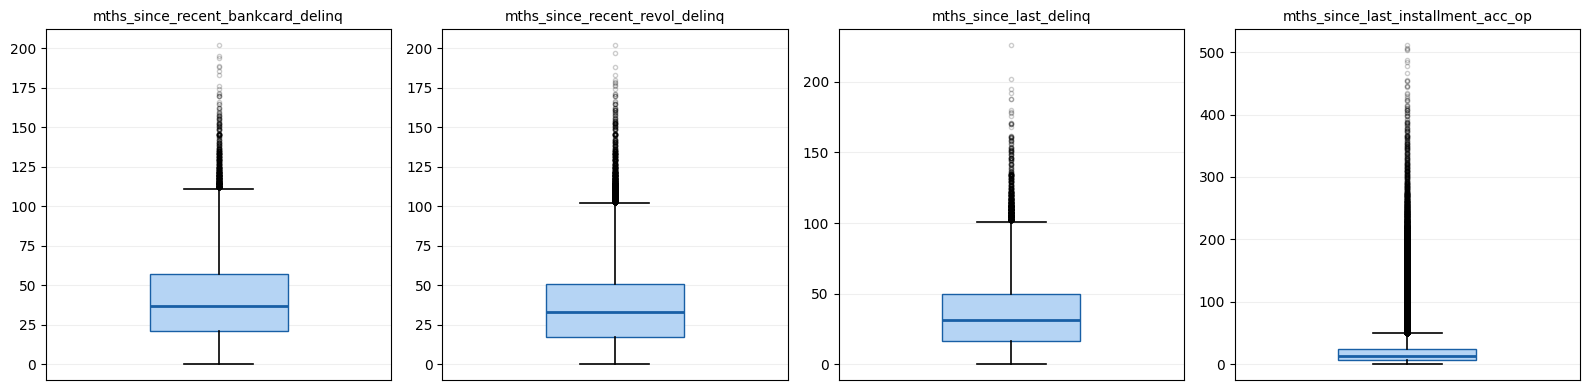

In [23]:
mths_since_cols = [
    "mths_since_recent_bankcard_delinq",
    "mths_since_recent_revol_delinq",
    "mths_since_last_delinq",
    "mths_since_last_installment_acc_op"
]

# Outlier check before sentinel imputation: mths_since_recent_bankcard_delinq only has 0.06% outliers
plot_boxplots_list(df=df_master_features_months, features=mths_since_cols)

In [24]:
# PD: impute NaNs with sentinel value 999
df_master_features_months["mths_since_recent_bankcard_delinq_PD"] = df_master_features_months["mths_since_recent_bankcard_delinq"]

df_master_features["mths_since_recent_bankcard_delinq_PD"]    = df_master_features_months["mths_since_recent_bankcard_delinq_PD"].fillna(999)
df_master_features["mths_since_recent_revol_delinq_PD"]       = df_master_features_months["mths_since_recent_revol_delinq"].fillna(999)
df_master_features["mths_since_last_delinq_PD"]               = df_master_features_months["mths_since_last_delinq"].fillna(999)
df_master_features["mths_since_last_installment_acc_op_PD"]   = df_master_features_months["mths_since_last_installment_acc_op"].fillna(999)

# LGD: same imputation
df_master_features["mths_since_recent_bankcard_delinq_LGD"]   = df_master_features_months["mths_since_recent_bankcard_delinq"].fillna(999)
df_master_features["mths_since_recent_revol_delinq_LGD"]      = df_master_features_months["mths_since_recent_revol_delinq"].fillna(999)
df_master_features["mths_since_last_delinq_LGD"]              = df_master_features_months["mths_since_last_delinq"].fillna(999)
df_master_features["mths_since_last_installment_acc_op_LGD"]  = df_master_features_months["mths_since_last_installment_acc_op"].fillna(999)

# Drop original columns
df_master_features = df_master_features.drop(columns=mths_since_cols)
del df_master_features_months

### 5.2 `emp_title`

Job title supplied by borrower. High cardinality with many low-frequency categories. Grouped into 12 professional categories using a normalized mapping. NaNs imputed as 'Unknown'.

In [25]:
df_master_features["emp_title"].value_counts().head(20)

emp_title
Teacher               34851
Manager               32600
Owner                 20802
Registered Nurse      14946
RN                    13981
Driver                13854
Supervisor            13460
Sales                 12398
Project Manager       10495
Office Manager         9067
General Manager        8845
Director               8641
owner                  8163
President              7413
Engineer               7006
manager                6833
teacher                6238
Operations Manager     5857
Vice President         5726
Accountant             5338
Name: count, dtype: int64

In [26]:
# Group emp_title into 12 high-level professional categories (min_freq=10)
df_master_features_aux = df_master_features.copy()
df_master_features_aux = group_emp_title(df_master_features_aux, col="emp_title", min_freq=10)

df_master_features["emp_title"] = df_master_features_aux["emp_title_grouped"]
del df_master_features_aux

→ Step 1: Normalizing text in 'emp_title'...


  Unique titles before normalization : 496,831


  Unique titles after normalization  : 382,829

→ Step 2: Frequency filter (min_freq=10)...


  Unique titles after frequency filter: 13,662

→ Step 3: Applying keyword-based semantic mapping...



✓ Done. Distribution of 'emp_title_grouped':
      category      n   pct
         Other 633744 29.62
    Management 397212 18.56
    Healthcare 206040  9.63
       Unknown 148666  6.95
       Finance 146602  6.85
  Construction 143160  6.69
    Government 121148  5.66
          Tech  75630  3.53
     Education  72548  3.39
Transportation  61978  2.90
         Admin  61116  2.86
         Sales  46075  2.15
   Hospitality  13336  0.62
         Legal  12388  0.58


### 5.3 `emp_length`

Employment length in years. Contains text formatting ('10+ years', '< 1 year'). NaNs treated as unemployment (imputed to 0).

In [27]:
df_master_features["emp_length"].value_counts()

emp_length
10+ years    714363
2 years      194813
3 years      172765
< 1 year     167859
1 year       142335
5 years      133519
4 years      130607
6 years       98444
7 years       89299
8 years       88624
9 years       76669
Name: count, dtype: int64

In [28]:
# Clean emp_length: convert to numeric, cap at 10, set < 1 year to 0.5, NaN to 0
df_master_features["emp_length"] = df_master_features["emp_length"].apply(clean_emp_length)

# Use unemployment information to update emp_title
df_master_features.loc[df_master_features["emp_length"] == 0, "emp_title"] = "Unemployed"

df_master_features["emp_length"].value_counts()
df_master_features["emp_title"].value_counts(normalize=True).round(2) * 100

emp_title
Other             30.0
Management        19.0
Healthcare        10.0
Finance            7.0
Construction       7.0
Unemployed         6.0
Government         6.0
Tech               4.0
Education          3.0
Transportation     3.0
Admin              3.0
Sales              2.0
Unknown            1.0
Hospitality        1.0
Legal              1.0
Name: proportion, dtype: float64

## 6. Checkpoint: Save Diagnosed Dataframe

In [29]:
os.makedirs("data/processed", exist_ok=True)

with open("data/processed/checkpoint_end_Data_Diagnosis.pkl", "wb") as f:
    pickle.dump({"df_master_features": df_master_features}, f)

print(f"Saved. Shape: {df_master_features.shape}")

Saved. Shape: (2139643, 54)


In [30]:
# Load checkpoint (run this cell to skip re-running the diagnosis)
with open("data/processed/checkpoint_end_Data_Diagnosis.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]